按下列要求完成程序，程序实现以下功能： 

1. 导入相关库。 

2. 利用make_blobs函数生成一个样本数量为50的数据集，用train_test_split函数将其划分为训练集和测试集，其中测试集占比为1/5。然后，对训练集进行标准化拟合和转换，对测试集进行标准化转换。 

3. 建立分类器对象，基于KNeighborsClassifier分类模型实现分类，利用训练集的特征数据和标签数据进行模型拟合。 

4. 基于测试集数据计算模型分类精度，用以衡量模型分类效果。 

5. 对未知类别的样本数据点[-1,1]调用分类模型的predict函数进行类别预测，并利用直线表示出与数据点[-1,1]距离最近的7个点。 

程序运行结果如样张所示。注意：考生只可补全代码，不可修改或删除横线处以外任何代码。 

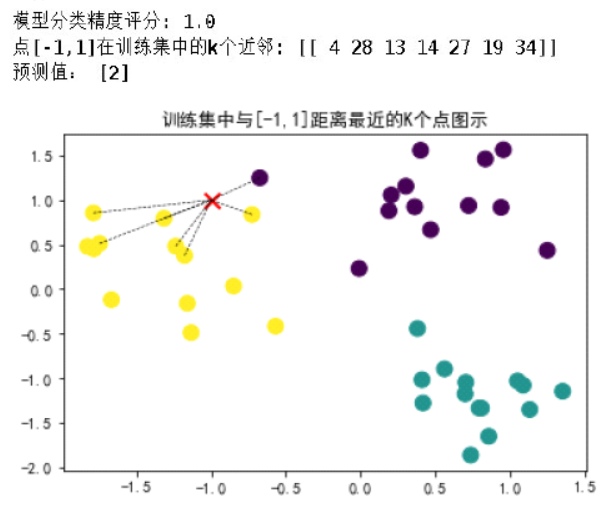

模型分类精度评分: 1.0
点[-1,1]在训练集中的k个近邻: [[ 4 28 13 14 27 19 34]]
预测值： [2]


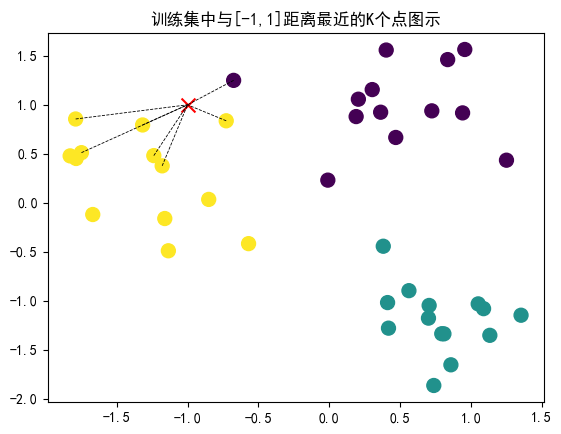

In [1]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split #【1】导入train_test_split
from matplotlib import pyplot as plt

#利用sklearn.datasets的make_blobs函数随机生成数量为50的样本数据集
X,Y=make_blobs(n_samples=50,random_state=0,cluster_std=0.6) # type: ignore
X_train,X_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=0) #【2】划分数据集为训练集和测试集

# 标准化数据
std = StandardScaler()
X_train = std.fit_transform(X_train)
X_test = std.transform(X_test)

clf=KNeighborsClassifier(n_neighbors=7) #【3】创建分类器对象，近邻数为7
clf.fit(X_train,y_train)

score=clf.score(X_test,y_test) #【4】基于测试集数据计算模型分类精度
print("模型分类精度评分:",score)

#对[-1,1]预测类别
X_sample=np.array([[-1,1]])
Y_sample=clf.predict(X_sample) #【5】对X_sample预测类别

#找到X_sample在训练集中的k个近邻
neighbors=clf.kneighbors(X_sample,return_distance=False)
print("点[-1,1]在训练集中的k个近邻:",neighbors)
print("预测值：",Y_sample)

#分类结果可视化，利用直线表示出训练集中与数据点[-1,1]距离最近的k个点
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams["axes.unicode_minus"]=False
plt.title("训练集中与[-1,1]距离最近的K个点图示")
plt.scatter(X_train[:,0],X_train[:,1],c=y_train,s=100)
plt.scatter(X_sample[:,0],X_sample[:,1],marker="x",c="red",s=100)
for i in neighbors[0]:
    plt.plot([X_train[i][0],X_sample[0][0]],[X_train[i][1],X_sample[0][1]],"k--",linewidth=0.6)
plt.show()